In [1]:
from huggingface_hub import hf_hub_download
import pandas as pd
import numpy as np

C:\Users\stlma\miniforge3\envs\ci\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
file_path = hf_hub_download(
    repo_id="cooperzvegintzov/OpenPoly",
    filename="experiment_polymer_data.xlsx",
    repo_type="dataset"
)

In [4]:
polymer_data = pd.read_excel(file_path)

In [12]:
print(polymer_data.head())
print(polymer_data.columns)

print("Example datapoint:")
print("SMILES:", polymer_data.iloc[0]["PSMILES"])
print("Tg:", polymer_data.iloc[0]["Tg_K"])

      id  Name               PSMILES  Atomization_Energy_eV  Bandgap_eV  \
0  16122   PLA      CC(C([*])=O)O[*]                    NaN    4.068600   
1  16123  PMMA  COC(C([*])(C[*])C)=O                    NaN    4.251094   
2  16124   PCL     [*]OCCCCCC([*])=O                    NaN    1.595000   
3  16125    PP           [*]CC(C)[*]                    NaN    2.323333   
4  16126   PVA           [*]CC([*])O                    NaN    4.348960   

   Bandgap_Bulk_eV  Bandgap_Chain_eV  CH4_Permeability_Barrer  \
0              NaN               NaN                      NaN   
1              NaN               NaN                      NaN   
2              NaN               NaN                      NaN   
3              NaN               NaN                      NaN   
4              NaN               NaN                      NaN   

   CO2_Permeability_Barrer  Compressive_Strength_MPa  ...  Refractive_Index  \
0                 1.100000                 21.018627  ...          1.456632   


In [8]:
import numpy as np
import pandas as pd

print("Total datapoints:", len(polymer_data))

# Treat blank strings as missing values
data_clean = polymer_data.replace(r'^\s*$', np.nan, regex=True)

# Count valid entries for every feature
feature_counts = pd.DataFrame({
    "Feature": data_clean.columns,
    "Viable Datapoints": data_clean.notna().sum().values,
    "Missing Datapoints": data_clean.isna().sum().values,
    "Percent Available": (
        data_clean.notna().mean().values * 100
    )
})

feature_counts = feature_counts.sort_values(
    "Viable Datapoints", ascending=False
)

print("\nViable datapoints per feature:")
print(feature_counts.to_string(index=False))

# Number of samples with a valid Tg measurement
tg_numeric = pd.to_numeric(
    data_clean["Tg_K"], errors="coerce"
).replace([np.inf, -np.inf], np.nan)

print("\nViable Tg datapoints:", tg_numeric.notna().sum())

print("Duplicate rows:", data_clean.duplicated().sum())

Total datapoints: 13116

Viable datapoints per feature:
                              Feature  Viable Datapoints  Missing Datapoints  Percent Available
                                   id              13116                   0         100.000000
                                 Name              13116                   0         100.000000
                              PSMILES              13116                   0         100.000000
                            Reference              13116                   0         100.000000
                                 Tg_K               8471                4645          64.585239
                     Bandgap_Chain_eV               3380                9736          25.770052
               O2_Permeability_Barrer                757               12359           5.771577
              CO2_Permeability_Barrer                706               12410           5.382739
               N2_Permeability_Barrer                678               12438    

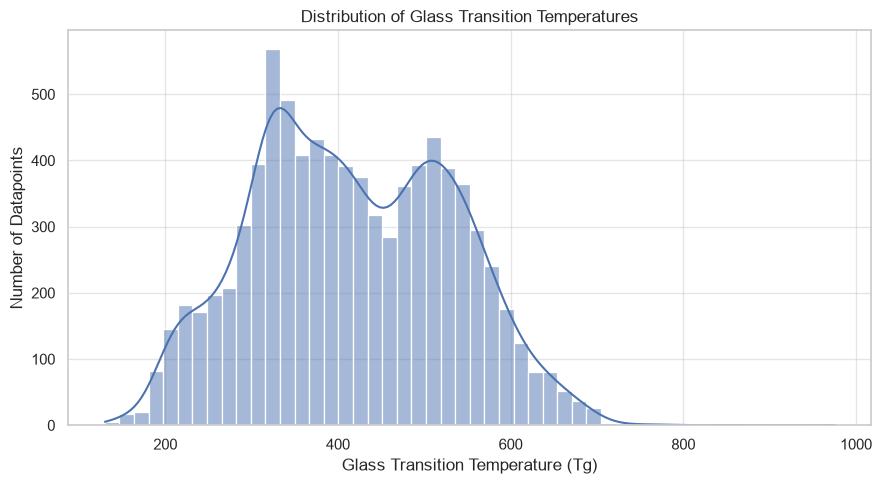

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

tg = tg_numeric.dropna()

plt.figure(figsize=(9, 5))

sns.histplot(tg, bins=50, kde=True)

plt.xlabel("Glass Transition Temperature (Tg)")
plt.ylabel("Number of Datapoints")
plt.title("Distribution of Glass Transition Temperatures")

plt.tight_layout()
plt.savefig("tg_distribution.png", dpi=300)
plt.show()

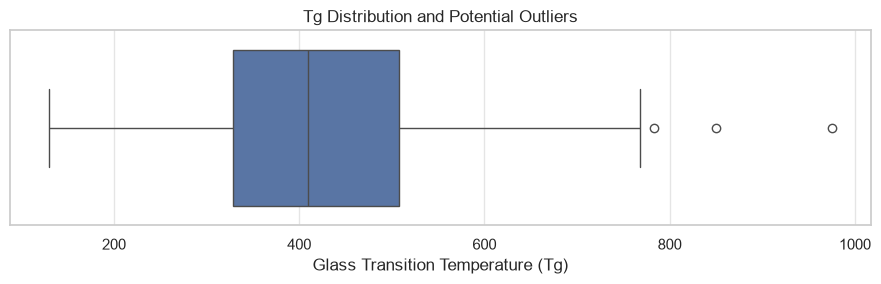

In [11]:
plt.figure(figsize=(9, 3))

sns.boxplot(x=tg)

plt.xlabel("Glass Transition Temperature (Tg)")
plt.title("Tg Distribution and Potential Outliers")

plt.tight_layout()
plt.savefig("tg_boxplot.png", dpi=300)
plt.show()